In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 27.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 3.6 MB/s eta 0:00:00


In [ ]:
# 1. Install Ultralytics (Kaggle environments sometimes need this updated)


from ultralytics import YOLO
import torch
import os

# 2. Verify GPU (Kaggle provides free GPUs, we want to make sure it's active)
device = 0 if torch.cuda.is_available() else 'cpu'
print(f"🚀 Training on device: {'GPU' if device == 0 else 'CPU'}")

# 3. Load the Nano Model for Transfer Learning
# We use the 'Nano' version to prevent the model from memorizing your small dataset.
model = YOLO('yolov8n.pt') 

# 4. Execute Training with Advanced Best Practices
results = model.train(
    # --- Core Configuration ---
    # IMPORTANT: Update this to point to your dataset's YAML file in Kaggle's /input directory
    data='data.yaml', 
    epochs=100,             # Set a high ceiling; Early Stopping will halt it naturally
    batch=16,               # 16 is perfectly stable for Kaggle's 16GB GPUs
    imgsz=640,              # Standard image size
    device=device,
    
    # --- Early Stopping & Regularization ---
    patience=15,            # EARLY STOPPING: Halts training if no improvement for 15 epochs
    dropout=0.1,            # Randomly drops nodes to force the network to generalize
    weight_decay=0.0005,    # L2 regularization to penalize overly complex weights
    
    # --- Aggressive Augmentation (Crucial for your 98 images) ---
    mosaic=1.0,             # 100% chance to stitch 4 images together (creates synthetic scenes)
    mixup=0.1,              # 10% chance to blend two images translucently
    degrees=15.0,           # Randomly rotate images up to 15 degrees
    translate=0.1,          # Randomly shift the image by 10%
    scale=0.5,              # Randomly zoom in/out by 50%
    fliplr=0.5,             # 50% chance of horizontal flipping
    hsv_h=0.015,            # Slight hue variation
    hsv_s=0.7,              # Saturation variation
    hsv_v=0.4,              # Brightness variation
    
    # --- Optimization ---
    optimizer='auto',       # Let the engine pick the best optimizer (usually AdamW for small data)
    lr0=0.001,              # Lower initial learning rate to prevent wild loss spikes early on
    
    # --- Infrastructure & Saving ---
    cache=True,             # Caches your 98 images in RAM for lightning-fast training[cite: 21]
    project='/dental_yolo', # Saves everything to Kaggle's output directory
    name='nano_run_1',
    plots=True              # Automatically generates the loss and metric graphs
)

print(f"✅ Training complete! Your best model is saved at: /kaggle/working/dental_yolo/nano_run_1/weights/best.pt")

🚀 Training on device: GPU
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/dental-research/dental-4/dental dataset/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.1, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scal

In [20]:
import shutil
from IPython.display import FileLink

# Define the target folder and the name of the zip file
folder_to_zip = '/kaggle/working/dental_xray_subset' 
zip_filename = '/kaggle/working/dental_yolo_latest'

# Compress the entire directory into a single .zip file
shutil.make_archive(zip_filename, 'zip', folder_to_zip)

print("✅ Folder successfully compressed! Click the link below to download:")

# Generate a clickable download link in the Kaggle output cell
FileLink('dental_yolo_latest.zip')

✅ Folder successfully compressed! Click the link below to download:


/kaggle/working/dental_yolo_latest.zip

In [16]:
from ultralytics import YOLO
import torch

# 1. Check for GPU
device = 0 if torch.cuda.is_available() else 'cpu'
print(f"🚀 Training on device: {'GPU' if device == 0 else 'CPU'}")

# 2. Initialize model
model = YOLO('yolov8n.pt') 

# 3. Define the dataset path
dataset_yaml_path = '/kaggle/input/datasets/dental-research/data-yaml/data.yaml'

# 4. Run training
results = model.train(
    data=dataset_yaml_path,
    fraction=[0.1, 0.1, 1.0],  # 10% Train, 10% Val, 100% Test           # <-- CRITICAL: Uses only the first 10% of the dataset's images
    epochs=50,              # Lowered to 50 for a faster subset test run
    batch=16,               
    imgsz=640,              
    device=device,
    
    # --- Execution & Memory Management ---
    cache=False,            # <-- CRITICAL: Prevents Kaggle Out-Of-Memory (OOM) crashes by loading from disk
    workers=4,              # Optimizes CPU usage during data loading
    
    # --- Regularization ---
    patience=15,            
    dropout=0.1,            
    weight_decay=0.0005,    
    
    # --- Augmentations ---
    mosaic=1.0,             
    mixup=0.05,             
    degrees=10.0,           
    translate=0.1,          
    scale=0.5,              
    fliplr=0.5,             
    
    # --- Saving & Output ---
    project='/kaggle/working/dental_xray_subset', 
    name='run_1',
    plots=True              
)

print(f"✅ Training complete! Best model saved at: /kaggle/working/dental_xray_subset/run_1/weights/best.pt")

🚀 Training on device: GPU
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/dental-research/data-yaml/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.1, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=[0.1, 0.1, 1.0], freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=

Running pathology inference on: /kaggle/input/datasets/lokisilvres/dental-disease-panoramic-detection-dataset/YOLO/YOLO/test/images/000dc27f-NAJIB_MARDANLOO_MASUME_2020-07-12185357_jpg.rf.f00e39f32edbca5c4cf42f39d9b0364c.jpg

image 1/1 /kaggle/input/datasets/lokisilvres/dental-disease-panoramic-detection-dataset/YOLO/YOLO/test/images/000dc27f-NAJIB_MARDANLOO_MASUME_2020-07-12185357_jpg.rf.f00e39f32edbca5c4cf42f39d9b0364c.jpg: 640x640 9 Crowns, 9 Fillings, 1 Missing teeth, 2 Periapical lesions, 8 Root Canal Treatments, 7.6ms
Speed: 1.3ms preprocess, 7.6ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

🩺 Total Conditions Detected: 29
Detected: Crown | Confidence: 0.93
Detected: Crown | Confidence: 0.91
Detected: Crown | Confidence: 0.91
Detected: Crown | Confidence: 0.79
Detected: Crown | Confidence: 0.79
Detected: Crown | Confidence: 0.75
Detected: Crown | Confidence: 0.75
Detected: Filling | Confidence: 0.74
Detected: Root Canal Treatment | Confidence: 0.73
Detected:

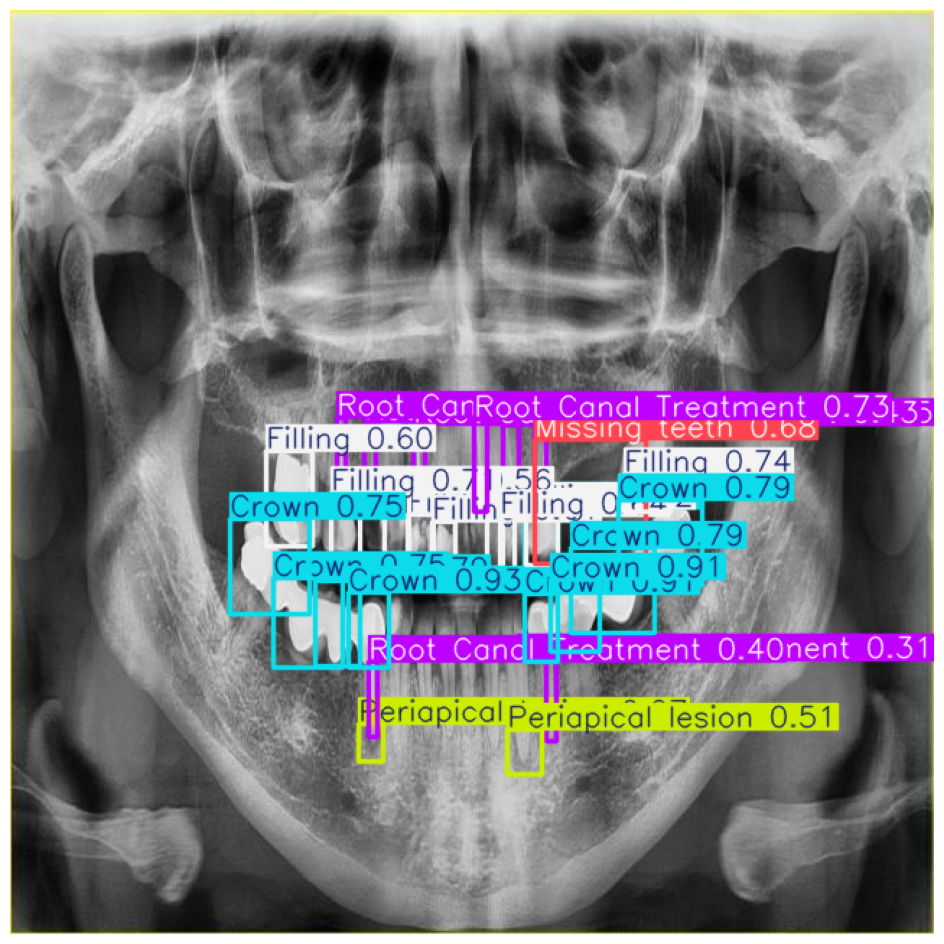

In [21]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

# 1. Load the new multi-class pathology model
# Note: The logs show the final save directory was run_1-2
model_path = '/kaggle/working/dental_xray_subset/run_1-2/weights/best.pt'
model = YOLO(model_path)

# 2. Define the test image (using the same one from your earlier tests)
test_image = '/kaggle/input/datasets/lokisilvres/dental-disease-panoramic-detection-dataset/YOLO/YOLO/test/images/000dc27f-NAJIB_MARDANLOO_MASUME_2020-07-12185357_jpg.rf.f00e39f32edbca5c4cf42f39d9b0364c.jpg'

# 3. Run Inference 
# Using a confidence threshold of 0.25 to filter out weak guesses
print(f"Running pathology inference on: {test_image}")
results = model.predict(source=test_image, conf=0.25, iou=0.45)

# 4. Display the detected conditions
for result in results:
    boxes = result.boxes
    print(f"\n🩺 Total Conditions Detected: {len(boxes)}")
    
    for box in boxes:
        # Get the class ID and look up the string name (e.g., 'Implant', 'Crown')
        class_id = int(box.cls[0].item())
        class_name = model.names[class_id]
        confidence = box.conf[0].item()
        print(f"Detected: {class_name} | Confidence: {confidence:.2f}")

# 5. Render the annotated image inline
annotated_img = results[0].plot() 
annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 12))
plt.imshow(annotated_img_rgb)
plt.axis('off')
plt.show()

Running inference on: /kaggle/input/datasets/lokisilvres/dental-disease-panoramic-detection-dataset/YOLO/YOLO/test/images/000dc27f-NAJIB_MARDANLOO_MASUME_2020-07-12185357_jpg.rf.f00e39f32edbca5c4cf42f39d9b0364c.jpg

image 1/1 /kaggle/input/datasets/lokisilvres/dental-disease-panoramic-detection-dataset/YOLO/YOLO/test/images/000dc27f-NAJIB_MARDANLOO_MASUME_2020-07-12185357_jpg.rf.f00e39f32edbca5c4cf42f39d9b0364c.jpg: 640x640 9 Crowns, 9 Fillings, 1 Missing teeth, 2 Periapical lesions, 8 Root Canal Treatments, 7.6ms
Speed: 0.9ms preprocess, 7.6ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


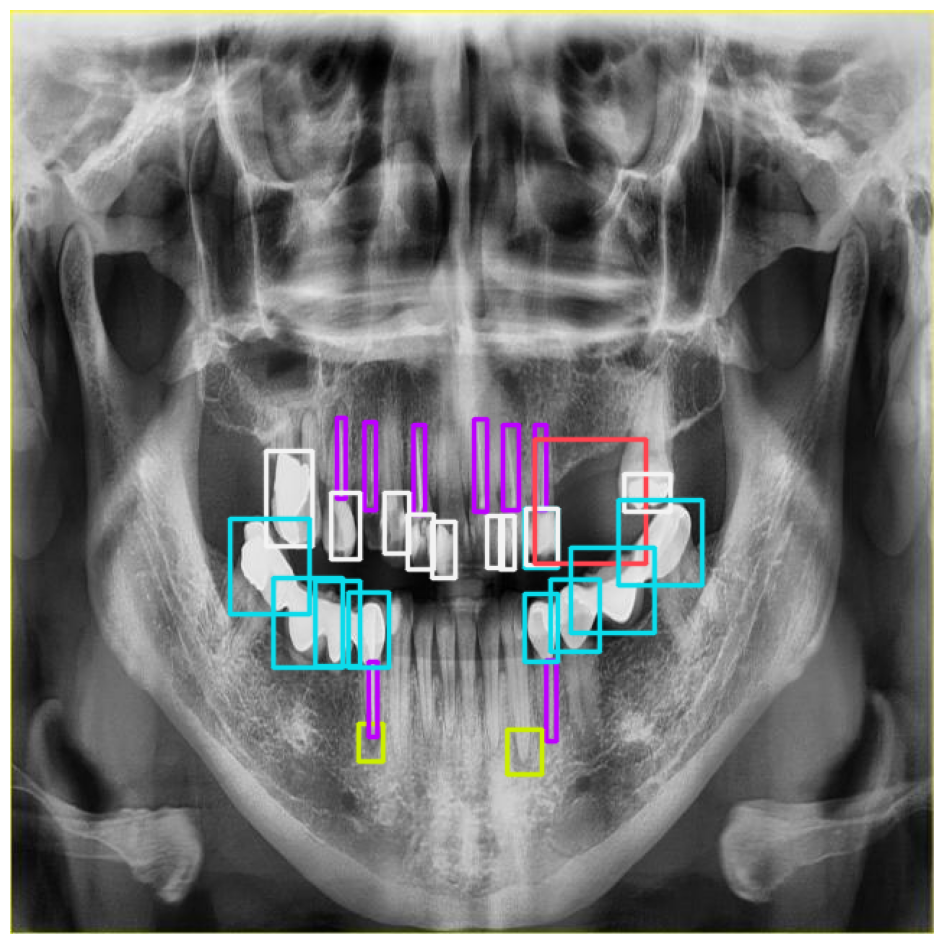

In [23]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

# 1. Load your trained model
model_path = '/kaggle/working/dental_xray_subset/run_1-2/weights/best.pt'
model = YOLO(model_path)

# 2. Define the test image
test_image = '/kaggle/input/datasets/lokisilvres/dental-disease-panoramic-detection-dataset/YOLO/YOLO/test/images/000dc27f-NAJIB_MARDANLOO_MASUME_2020-07-12185357_jpg.rf.f00e39f32edbca5c4cf42f39d9b0364c.jpg'

# 3. Run Inference
print(f"Running inference on: {test_image}")
results = model.predict(source=test_image, conf=0.25, iou=0.45)

# 4. Render the image with ONLY boxes (labels=False, conf=False)
annotated_img = results[0].plot(labels=False, conf=False, line_width=2) 

# 5. Convert format and display inline
annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 12))
plt.imshow(annotated_img_rgb)
plt.axis('off') # Hides the axis numbers
plt.show()